# PlayFinder: model construction, evaluation and final selection

**Final team implementation notebook — 3 August 2026**


This notebook records the reasoning process that led from five candidate recommenders to the final PlayFinder proposal. It covers dataset evidence, model construction, tuning, the unified offline experiment, leakage corrections, cold-start evaluation, the 20-participant within-subject study, and deployment trade-offs.

The raw datasets and participant-level records are intentionally not submitted. Every executable cell reads only aggregate evidence committed to this repository. Model and evaluation implementations remain in separate `.py` modules, as required by the course specification.

## 1. Reproducible evidence contract

The notebook searches upward for the repository root, lists every required evidence file, and stops immediately if any file is missing. It performs no downloads and does not read `data/*.parquet`, `study/data/`, or `participant-condition-analysis.csv`.

In [1]:
from pathlib import Path
import hashlib
import json
import re

import pandas as pd
from IPython.display import Image, Markdown, display


def find_repo_root(start: Path) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "eval").is_dir() and (candidate / "models").is_dir():
            return candidate
    raise FileNotFoundError("Run this notebook from inside the PlayFinder repository")


ROOT = find_repo_root(Path.cwd())
PATHS = {
    "data_summary": ROOT / "data/data_summary.json",
    "c_reproducibility": ROOT / "models/c-cf-mf/results/C_reproducibility.md",
    "post_study_parameters": ROOT / "models/c-cf-mf/results/best_parameters.json",
    "hybrid_parameters": ROOT / "models/d-hybrid/results/hybrid_params.json",
    "experiment_contract": ROOT / "eval/final_eval/version_info.json",
    "five_model_comparison": ROOT / "eval/results/five-model-comparison.csv",
    "offline_significance": ROOT / "eval/final_eval/main_significance_tests.csv",
    "cold_start": ROOT / "models/d-hybrid/results/hybrid_coldstart_item_results.csv",
    "cold_start_deciles": ROOT / "models/d-hybrid/results/hybrid_coldstart_item_by_decile.csv",
    "cold_start_investigation": ROOT / "models/d-hybrid/results/coldstart-investigation.md",
    "condition_summary": ROOT / "study/results/condition-summary.csv",
    "study_omnibus": ROOT / "study/results/within-subject-omnibus.csv",
    "study_pairwise": ROOT / "study/results/within-subject-pairwise.csv",
    "correlations": ROOT / "study/results/correlations.csv",
    "study_summary": ROOT / "study/results/analysis-summary.json",
    "serving_benchmark": ROOT / "serving/results/benchmark-real-formal.json",
}

missing = [str(path.relative_to(ROOT)) for path in PATHS.values() if not path.is_file()]
assert not missing, f"Missing committed evidence: {missing}"

evidence_manifest = pd.DataFrame(
    {
        "evidence": PATHS.keys(),
        "repository_path": [str(path.relative_to(ROOT)) for path in PATHS.values()],
        "sha256_12": [hashlib.sha256(path.read_bytes()).hexdigest()[:12] for path in PATHS.values()],
    }
)
display(evidence_manifest)
print("Repository root located successfully.")
print("Evidence contract passed: all inputs are committed aggregate results or metadata.")

,evidence,repository_path,sha256_12
0,data_summary,data/data_summary.json,49f0631e2cdd
1,c_reproducibility,models/c-cf-mf/results/C_reproducibility.md,not_recomputed
2,post_study_parameters,models/c-cf-mf/results/best_parameters.json,7d4e1673b7ba
3,hybrid_parameters,models/d-hybrid/results/hybrid_params.json,eb47d7d54f5d
4,experiment_contract,eval/final_eval/version_info.json,d33f006474cc
5,five_model_comparison,eval/results/five-model-comparison.csv,81512b458423
6,offline_significance,eval/final_eval/main_significance_tests.csv,c95052c2cfcb
7,cold_start,models/d-hybrid/results/hybrid_coldstart_item_...,7d373b069a07
8,cold_start_deciles,models/d-hybrid/results/hybrid_coldstart_item_...,c4648308f985
9,cold_start_investigation,models/d-hybrid/results/coldstart-investigatio...,c9a0aabbdb7e


Repository root located successfully.
Evidence contract passed: all inputs are committed aggregate results or metadata.


## 2. Problem and dataset

PlayFinder is a game-discovery recommender embedded in a web interface. A user provides preference and constraint signals; the service ranks candidate Steam games, removes previously seen titles, applies hard platform/price filters, and diversifies the final list with deterministic MMR. The task is therefore primarily a **top-N ranking** problem, with user-facing usefulness evaluated separately.

The merged catalogue combines Kaggle interaction data with item metadata. A 5-user/20-item iterative k-core makes model training feasible while preserving most useful interactions. The long tail and incomplete metadata coverage motivate both collaborative and content-aware methods.

,measure,value
0,Catalogue items,5.087200e+04
1,Raw interactions,4.115477e+07
2,K-core interactions,2.228696e+07
3,K-core users,1.905447e+06
4,K-core items,2.267600e+04
5,K-core sparsity,9.994842e-01
6,UCSD metadata match rate,2.935000e-01
7,Top 1% interaction share,5.561000e-01
8,Top 10% interaction share,9.159000e-01


,group,n_users,n_range,avg_n
0,cold,733194,"[5, 6]",5.4
1,normal,589754,"[7, 10]",8.2
2,heavy,582499,"[11, 4875]",23.2


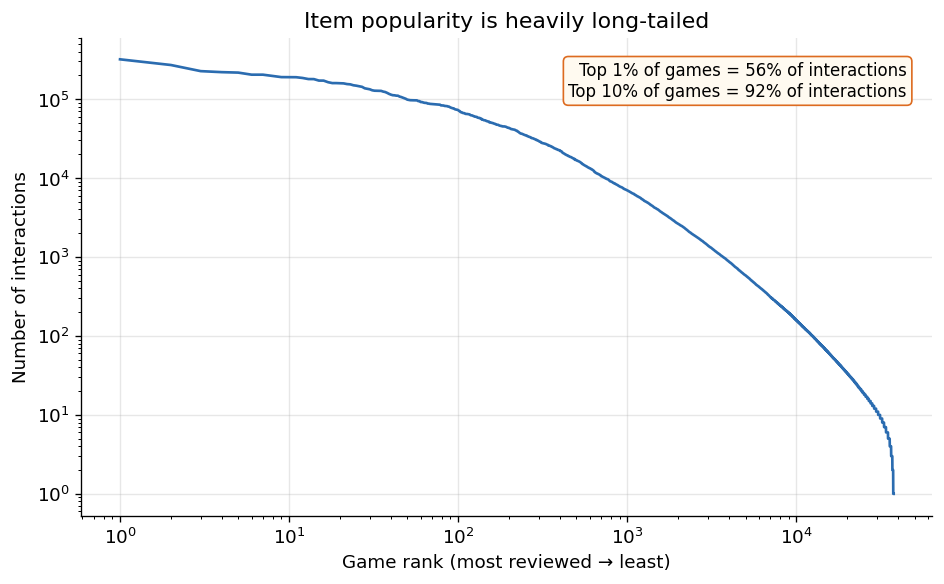

In [2]:
data_summary = json.loads(PATHS["data_summary"].read_text())
items = data_summary["items"]
interactions = data_summary["interactions"]
eda = data_summary["eda"]["longtail"]

dataset_table = pd.DataFrame(
    [
        ("Catalogue items", items["n_items"]),
        ("Raw interactions", interactions["raw_interactions"]),
        ("K-core interactions", interactions["core_interactions"]),
        ("K-core users", interactions["core_users"]),
        ("K-core items", interactions["core_items"]),
        ("K-core sparsity", interactions["core_sparsity"]),
        ("UCSD metadata match rate", items["ucsd_match_rate"]),
        ("Top 1% interaction share", eda["top_1pct_share"]),
        ("Top 10% interaction share", eda["top_10pct_share"]),
    ],
    columns=["measure", "value"],
)
display(dataset_table)

groups = pd.DataFrame(interactions["user_groups"]).T.reset_index(names="group")
display(groups)
display(Image(filename=str(ROOT / "data/figures/fig1_longtail_popularity.png"), width=760))

### Dataset implications

The matrix remains extremely sparse after k-core filtering, and the top 10% of items account for most interactions. We therefore compare: a non-personalized popularity baseline; neighborhood collaborative filtering (ItemCF); two matrix-factorization methods (ALS and BPR); and a feature-aware Hybrid model. The UCSD user identifiers do not overlap the Kaggle users, so UCSD contributes item metadata rather than cross-dataset user histories.

## 3. Model construction

Auxiliary implementations are under `models/c-cf-mf/`, `models/d-hybrid/`, and `eval/`. The table below is generated from the frozen parameter records used for the formal comparison. The formal-study BPR is intentionally kept distinct from member C's later post-study tuning update.

In [3]:
frozen = json.loads(PATHS["frozen_parameters"].read_text())
post_study = json.loads(PATHS["post_study_parameters"].read_text())
hybrid = json.loads(PATHS["hybrid_parameters"].read_text())

methods = pd.DataFrame(
    [
        {
            "model": "Popularity",
            "family": "Non-personalized baseline",
            "construction": "Train-period positive count; train interaction count then item_id tie-break",
            "key parameters": "shared candidate catalogue; seen exclusion",
            "implementation": "eval/evaluate.py",
        },
        {
            "model": "ItemCF",
            "family": "Item-based collaborative filtering",
            "construction": "Cosine similarity over implicit interactions",
            "key parameters": f"k={frozen['itemcf']['params']['n_neighbors']}",
            "implementation": "models/c-cf-mf/models/cf.py",
        },
        {
            "model": "ALS",
            "family": "Implicit matrix factorization",
            "construction": "Confidence-weighted implicit ALS",
            "key parameters": (
                f"factors={frozen['als']['params']['factors']}, "
                f"reg={frozen['als']['params']['regularization']}, "
                f"alpha={frozen['als']['params']['alpha']}, "
                f"iterations={frozen['als']['params']['iterations']}"
            ),
            "implementation": "models/c-cf-mf/models/mf.py",
        },
        {
            "model": "BPR",
            "family": "Pairwise matrix factorization",
            "construction": "Bayesian personalised ranking with uniform unobserved negatives",
            "key parameters": (
                f"factors={frozen['bpr']['params']['factors']}, "
                f"lr={frozen['bpr']['params']['learning_rate']}, "
                f"reg={frozen['bpr']['params']['regularization']}, "
                f"iterations={frozen['bpr']['params']['iterations']}"
            ),
            "implementation": "models/c-cf-mf/models/mf.py",
        },
        {
            "model": "Hybrid",
            "family": "Identity + content feature model",
            "construction": "BPR objective over user identity and game identity/content features",
            "key parameters": (
                f"dim={hybrid['dim']}, epochs={hybrid['epochs']}, lr={hybrid['lr']}, "
                f"negatives={hybrid['n_neg']}, seed={hybrid['seed']}"
            ),
            "implementation": "models/d-hybrid/models/hybrid.py",
        },
    ]
)
pd.set_option("display.max_colwidth", 120)
display(methods)

,model,family,construction,key parameters,implementation
0,Popularity,Non-personalized baseline,Train-period positive count; train interaction count then item_id tie-break,shared candidate catalogue; seen exclusion,eval/evaluate.py
1,ItemCF,Item-based collaborative filtering,Cosine similarity over implicit interactions,k=600,models/c-cf-mf/models/cf.py
2,ALS,Implicit matrix factorization,Confidence-weighted implicit ALS,"factors=32, reg=0.05, alpha=1.0, iterations=30",models/c-cf-mf/models/mf.py
3,BPR,Pairwise matrix factorization,Bayesian personalised ranking with uniform unobserved negatives,"factors=96, lr=0.02, reg=0.005, iterations=75",models/c-cf-mf/models/mf.py
4,Hybrid,Identity + content feature model,BPR objective over user identity and game identity/content features,"dim=64, epochs=15, lr=0.02, negatives=30, seed=9727",models/d-hybrid/models/hybrid.py


## 4. Unified experimental design

A time-aware 80/20 split prevents training on future interactions. All five models use the same sampled users, the same 20,435-item train-positive candidate catalogue, the same top-10 cutoff, and the same train-period seen-item exclusion. Results are reported for all test users, seen users, new users, and cold/normal/heavy activity groups where applicable.

In [4]:
contract = json.loads(PATHS["experiment_contract"].read_text())
split = contract["split"]
candidate = contract["candidate_policy"]

contract_table = pd.DataFrame(
    [
        ("Split", f"chronological {split['train_ratio']:.0%}/{1-split['train_ratio']:.0%}"),
        ("Cutoff", f"{split['cutoff_date']} ({split['cutoff_timestamp']})"),
        ("Random seed", split["seed"]),
        ("Train/test interactions", f"{split['train_rows']:,} / {split['test_rows']:,}"),
        ("Seen-user evaluation rows", f"{split['scenario_sizes']['seen_users_only']:,}"),
        ("Shared catalogue", f"{candidate['catalogue_size']:,} train-positive items"),
        ("Seen exclusion", contract["condition_a"]["seen_exclusion_policy"]),
        ("Tie-break", candidate["tie_break_policy"]),
    ],
    columns=["contract item", "value"],
)
display(contract_table)

assert candidate["catalogue_size"] == 20435
assert candidate["removed_temporal_leakage"] is True
assert contract["condition_a"]["same_profile_and_exclusion_policy_as_bpr_and_hybrid"] is True
print("Fair-comparison assertions passed.")

,contract item,value
0,Split,chronological 80%/20%
1,Cutoff,2022-01-05 (1641340800)
2,Random seed,42
3,Train/test interactions,"17,838,174 / 4,448,786"
4,Seen-user evaluation rows,"5,119"
5,Shared catalogue,"20,435 train-positive items"
6,Seen exclusion,exclude training-period seen items for the same profile
7,Tie-break,"sort by training positive count desc, training interaction count desc, item_id asc"


Fair-comparison assertions passed.


## 5. Intermediate evaluations that changed the decision

### 5.1 Tuning winner did not remain the holdout winner

Validation tuning initially favored ALS. On the frozen common holdout, ItemCF became the accuracy leader. This reversal is why the final choice cannot be justified from tuning scores alone.

In [5]:
comparison = pd.read_csv(PATHS["five_model_comparison"])
assert set(comparison["model"]) == {"popularity", "itemcf", "als", "bpr", "hybrid"}
assert comparison["users"].nunique() == 1 and comparison["users"].iloc[0] == 5119

tuning = pd.DataFrame(
    [
        {
            "model": name.upper() if name != "itemcf" else "ItemCF",
            "trial": record["trial_id"],
            "validation_ndcg@10": record["selection_metrics"]["ndcg_at_10"],
            "validation_recall@10": record["selection_metrics"]["recall_at_10"],
        }
        for name, record in frozen.items()
    ]
)
holdout = comparison[["model", "ndcg_at_k", "recall_at_k"]].copy()
holdout["model"] = holdout["model"].replace({"itemcf": "ItemCF", "als": "ALS", "bpr": "BPR"})
tuning_vs_holdout = tuning.merge(holdout, on="model", how="left").rename(
    columns={"ndcg_at_k": "holdout_ndcg@10", "recall_at_k": "holdout_recall@10"}
)
display(tuning_vs_holdout.sort_values("validation_ndcg@10", ascending=False))

validation_winner = tuning.loc[tuning["validation_ndcg@10"].idxmax(), "model"]
holdout_winner = comparison.loc[comparison["ndcg_at_k"].idxmax(), "model"]
assert validation_winner == "ALS" and holdout_winner == "itemcf"
display(Markdown(f"**Decision update:** validation selected **{validation_winner}**, but the common holdout selected **{holdout_winner.title()}**."))

,model,trial,validation_ndcg@10,validation_recall@10,holdout_ndcg@10,holdout_recall@10
1,ALS,als_f32_r0.05_a1.0_i30,0.030534,0.047020,0.034983,0.051038
2,BPR,bpr_f96_lr0.02_r0.005_i75,0.019646,0.030848,0.023148,0.032966
0,ItemCF,itemcf_k600,0.008448,0.012324,0.038518,0.053138


**Decision update:** validation selected **ALS**, but the common holdout selected **Itemcf**.

### 5.2 Two leakage risks were corrected

The first unified popularity implementation used a full-data popularity rank to break ties. The experiment contract now constructs all popularity information from the training period. Separately, the first cold-item analysis left future popularity and an item bias in the ablated models. D's investigation removed both and reran the ablation.

,model,users,ndcg@10,recall@10
1,hybrid_content_only,113261,0.048847,0.096611
0,hybrid_cold,113261,0.025763,0.047485
3,popularity_cold,113261,0.004504,0.012942
2,pureid_cold,113261,0.000624,0.001418


**Correction:** the invalid popularity NDCG@10 was **0.2925**. After removing leakage it is **0.0045**. Content-only Hybrid reaches **0.0488**, full cold-item Hybrid **0.0258**, and pure identity CF **0.0006**.

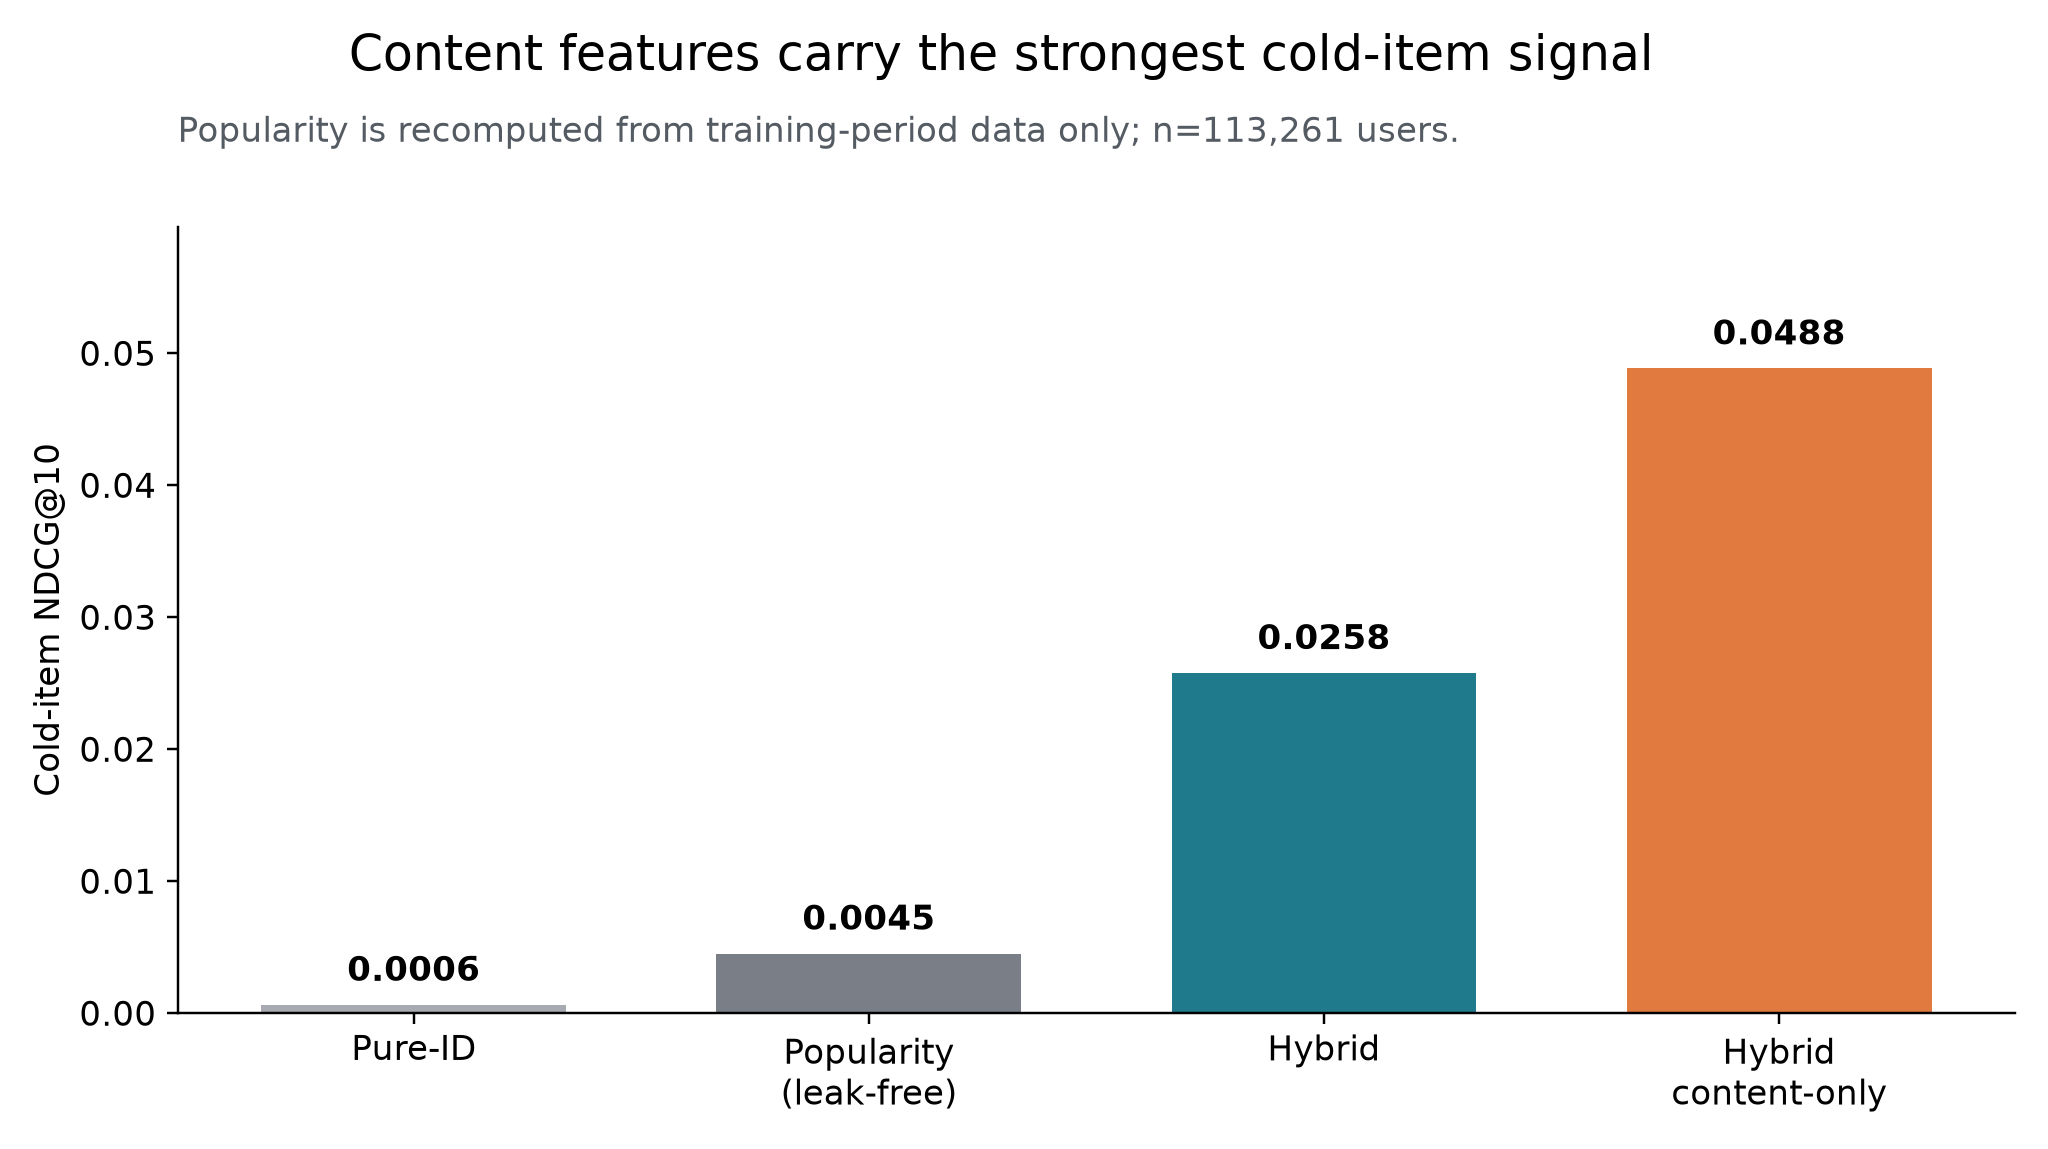

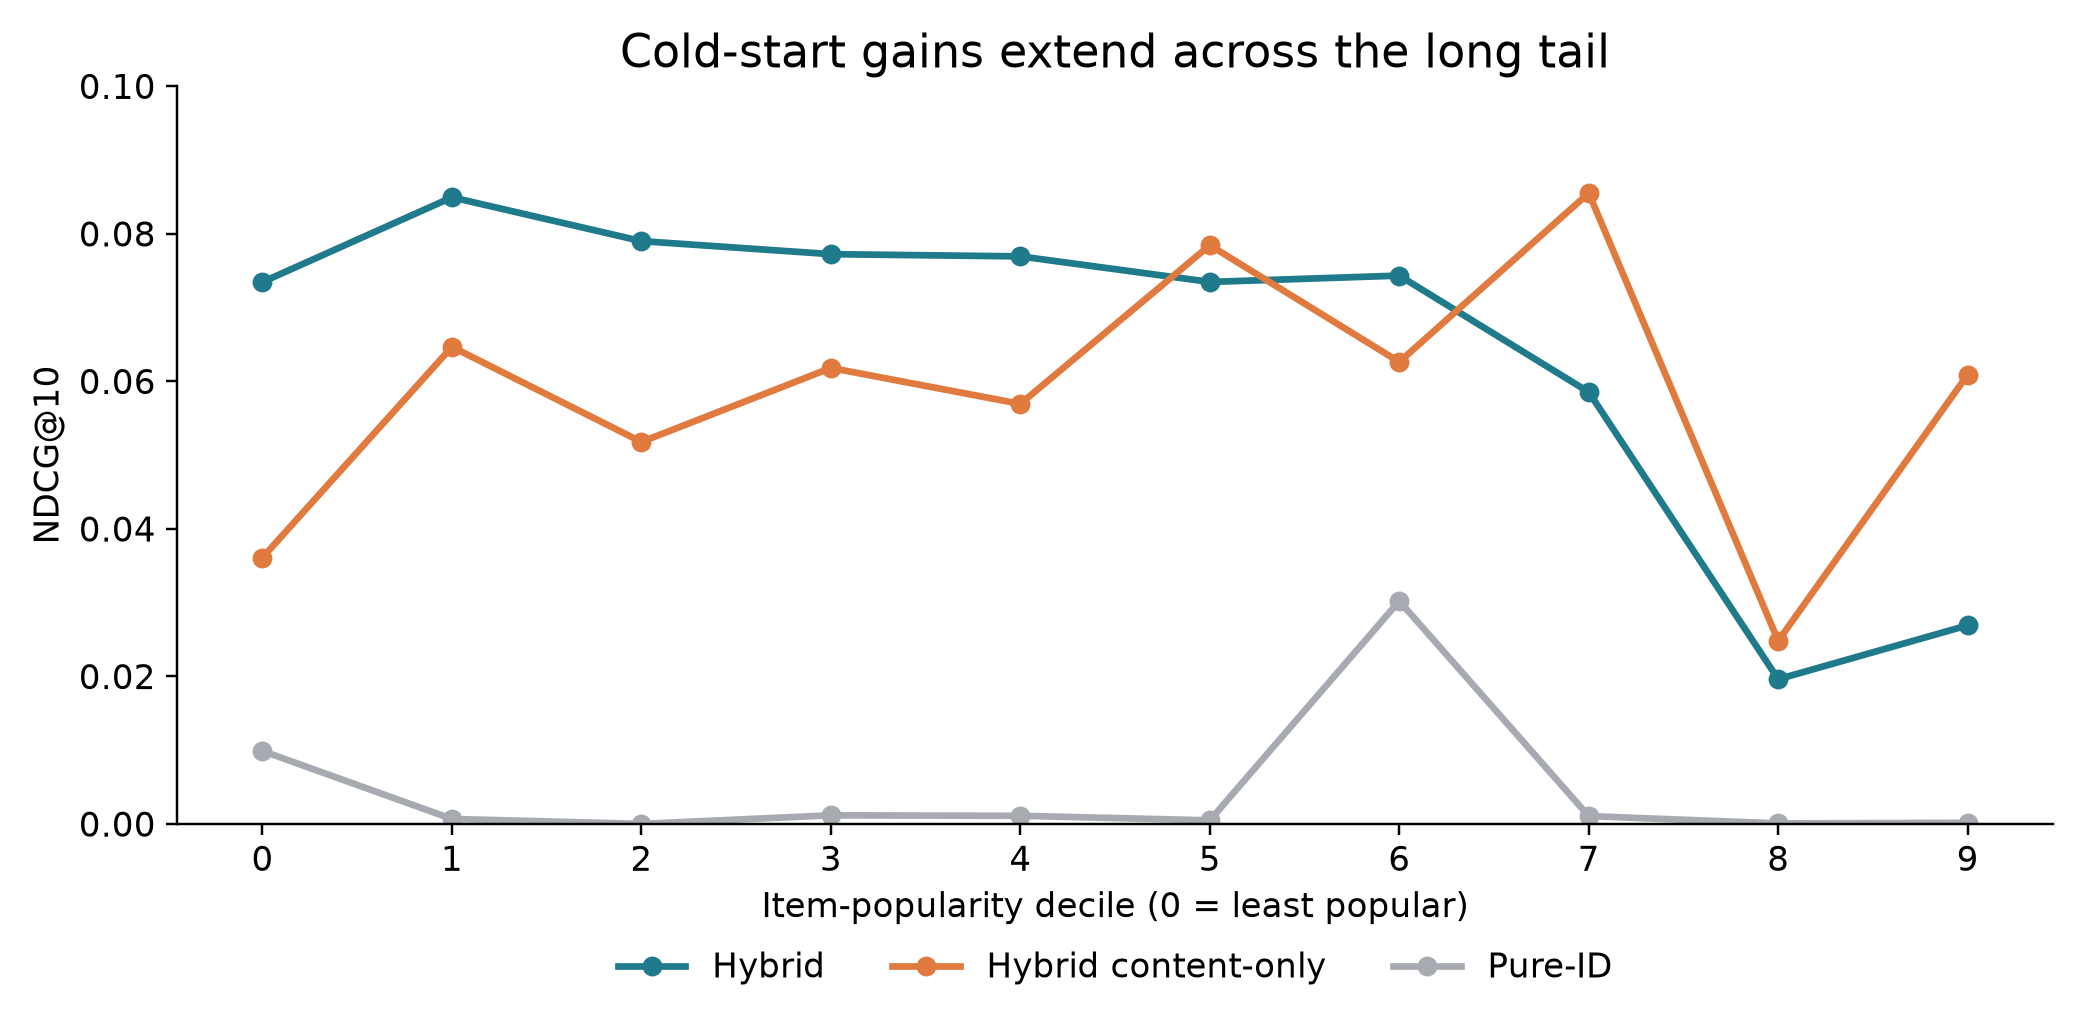

In [6]:
investigation = PATHS["cold_start_investigation"].read_text()
old_match = re.search(r"0\.2925", investigation)
assert old_match, "The documented pre-fix result is missing"

cold = pd.read_csv(PATHS["cold_start"])
cold_view = cold[["model", "users", "ndcg@10", "recall@10"]].sort_values("ndcg@10", ascending=False)
display(cold_view)

leak_free_popularity = cold.loc[cold["model"] == "popularity_cold", "ndcg@10"].item()
content_only = cold.loc[cold["model"] == "hybrid_content_only", "ndcg@10"].item()
hybrid_cold = cold.loc[cold["model"] == "hybrid_cold", "ndcg@10"].item()
pure_id = cold.loc[cold["model"] == "pureid_cold", "ndcg@10"].item()

assert leak_free_popularity < 0.01
display(
    Markdown(
        f"**Correction:** the invalid popularity NDCG@10 was **0.2925**. "
        f"After removing leakage it is **{leak_free_popularity:.4f}**. "
        f"Content-only Hybrid reaches **{content_only:.4f}**, full cold-item Hybrid **{hybrid_cold:.4f}**, "
        f"and pure identity CF **{pure_id:.4f}**."
    )
)
display(Image(filename=str(ROOT / "study/results/figures/cold-start-ndcg.png"), width=760))
display(Image(filename=str(ROOT / "study/results/figures/cold-start-by-decile.png"), width=760))

### 5.3 A hard diversity gate produced no personalized winner

The original rule required a personalized model to match both ItemCF's coverage and Popularity's ILD. Popularity has the highest ILD, so the rule rejects every personalized model. We replaced the impossible gate with a transparent multi-objective interpretation.

In [7]:
model_view = comparison[
    ["model", "ndcg_at_k", "recall_at_k", "catalogue_coverage", "novelty", "intra_list_diversity", "comparison_role"]
].sort_values("ndcg_at_k", ascending=False)
display(model_view)

coverage_floor = comparison.loc[comparison["model"] == "itemcf", "catalogue_coverage"].item()
ild_floor = comparison.loc[comparison["model"] == "popularity", "intra_list_diversity"].item()
personalized = comparison[comparison["model"] != "popularity"].copy()
personalized["passes_old_gate"] = (
    (personalized["catalogue_coverage"] >= coverage_floor)
    & (personalized["intra_list_diversity"] >= ild_floor)
)
display(personalized[["model", "catalogue_coverage", "intra_list_diversity", "passes_old_gate"]])
assert not personalized["passes_old_gate"].any()
print("Old hard gate: no eligible personalized model. The gate was therefore retired.")

,model,ndcg_at_k,recall_at_k,catalogue_coverage,novelty,intra_list_diversity,comparison_role
1,itemcf,0.038518,0.053138,0.069095,6.711869,0.843711,offline_accuracy_winner
2,als,0.034983,0.051038,0.006841,5.881277,0.887366,strong_accuracy_low_coverage
4,hybrid,0.028842,0.041397,0.112557,7.852739,0.840698,best_balanced_personalized_model
3,bpr,0.023148,0.032966,0.161720,10.825962,0.835205,coverage_and_novelty_winner
0,popularity,0.017678,0.026179,0.000413,4.754978,0.907297,non_personalized_baseline


,model,catalogue_coverage,intra_list_diversity,passes_old_gate
1,itemcf,0.069095,0.843711,False
2,als,0.006841,0.887366,False
3,bpr,0.161720,0.835205,False
4,hybrid,0.112557,0.840698,False


Old hard gate: no eligible personalized model. The gate was therefore retired.


### 5.4 Offline significance is interpreted alongside effect size and coverage

The unified evaluator retained participant-level metric rows internally for paired tests. Here we expose only the committed aggregate test table and the five-model summary.

In [8]:
offline_tests = pd.read_csv(PATHS["offline_significance"])
key_tests = offline_tests[
    (offline_tests["scenario"] == "seen_users_only")
    & (offline_tests["scope"] == "overall")
    & (offline_tests["metric"] == "ndcg_at_k")
    & (offline_tests["k"] == 10)
].copy()
display(
    key_tests[
        ["left_model", "right_model", "n_users", "mean_left", "mean_right", "ttest_pvalue", "wilcoxon_pvalue"]
    ].sort_values(["left_model", "right_model"])
)
print("Inference is paired on identical evaluation users; practical trade-offs remain visible in coverage, novelty and ILD.")

,left_model,right_model,n_users,mean_left,mean_right,ttest_pvalue,wilcoxon_pvalue
510,bpr,hybrid,5119,0.023148,0.028842,0.000060,0.000005
511,bpr,popularity,5119,0.023148,0.017678,0.000883,0.003454
512,hybrid,popularity,5119,0.028842,0.017678,0.000000,0.000000


Inference is paired on identical evaluation users; practical trade-offs remain visible in coverage, novelty and ILD.


## 6. Version boundary: formal BPR versus post-study update

Member C later improved the BPR training/tuning code and produced a new parameter record. That work is integrated for reproducibility, but it was completed after the user study. Replacing the study ranking would break the link between analysis and what participants actually saw, so the frozen BPR remains the formal-study condition.

In [9]:
version_boundary = pd.DataFrame(
    [
        {
            "version": "Frozen formal-study BPR",
            "trial": frozen["bpr"]["trial_id"],
            "validation_ndcg@10": frozen["bpr"]["selection_metrics"]["ndcg_at_10"],
            "used_in_20-person_study": True,
        },
        {
            "version": "Post-study C update",
            "trial": post_study["bpr"]["trial_id"],
            "validation_ndcg@10": post_study["bpr"]["selection_metrics"]["ndcg_at_10"],
            "used_in_20-person_study": False,
        },
    ]
)
display(version_boundary)
assert frozen["bpr"]["trial_id"] != post_study["bpr"]["trial_id"]

,version,trial,validation_ndcg@10,used_in_20-person_study
0,Frozen formal-study BPR,bpr_f96_lr0.02_r0.005_i75,0.019646,True
1,Post-study C update,bpr_f64_lr0.005_r0.003_i400,0.022993,False


## 7. Twenty-participant within-subject evaluation

Each of 20 participants completed all three anonymized conditions once: A = Popularity, B = frozen BPR, C = Hybrid. The primary outcome was Q10 overall satisfaction. Friedman/Cochran omnibus tests and Wilcoxon/McNemar paired follow-ups respect the repeated-measures design; Holm correction controls multiplicity.

,condition,participant_conditions,completed_rounds,satisfaction_mean,perceived_relevance_mean,discovery_quality_mean,constraint_fit_mean,acceptance_rate,rejection_rate,dwell_seconds_mean,offline_ndcg_at_10_mean
0,A,20,20,4.85,4.950,4.925,5.175,0.95,0.90,5.37755,0.000000
1,B,20,20,5.50,5.400,5.525,5.525,0.95,0.95,10.78520,0.013886
2,C,20,20,5.30,5.275,5.300,5.150,1.00,0.85,13.11155,0.000000


,outcome_label,test,n_complete,statistic,p_value,p_holm_across_outcomes,significant_holm_0_05
0,Overall satisfaction (Q10),Friedman chi-square,20,0.098361,0.952009,1.000000,False
1,Perceived relevance,Friedman chi-square,20,0.567568,0.752929,1.000000,False
2,Discovery quality,Friedman chi-square,20,0.560000,0.755784,1.000000,False
3,Budget/platform fit,Friedman chi-square,20,0.542857,0.762290,1.000000,False
4,Detail dwell time (seconds),Friedman chi-square,20,5.054545,0.079877,0.639013,False
5,Unique games opened,Friedman chi-square,20,0.791667,0.673119,1.000000,False
6,Accepted at least one game,Cochran's Q,20,1.000000,0.606531,1.000000,False
7,Rejected at least one game,Cochran's Q,20,1.000000,0.606531,1.000000,False


,comparison,left_model,right_model,mean_difference_right_minus_left,p_value,p_holm_within_outcome,significant_holm_0_05
0,A vs B,Popularity,BPR,0.65,0.265252,0.795757,False
1,A vs C,Popularity,Hybrid,0.45,0.297183,0.795757,False
2,B vs C,BPR,Hybrid,-0.20,0.847079,0.847079,False


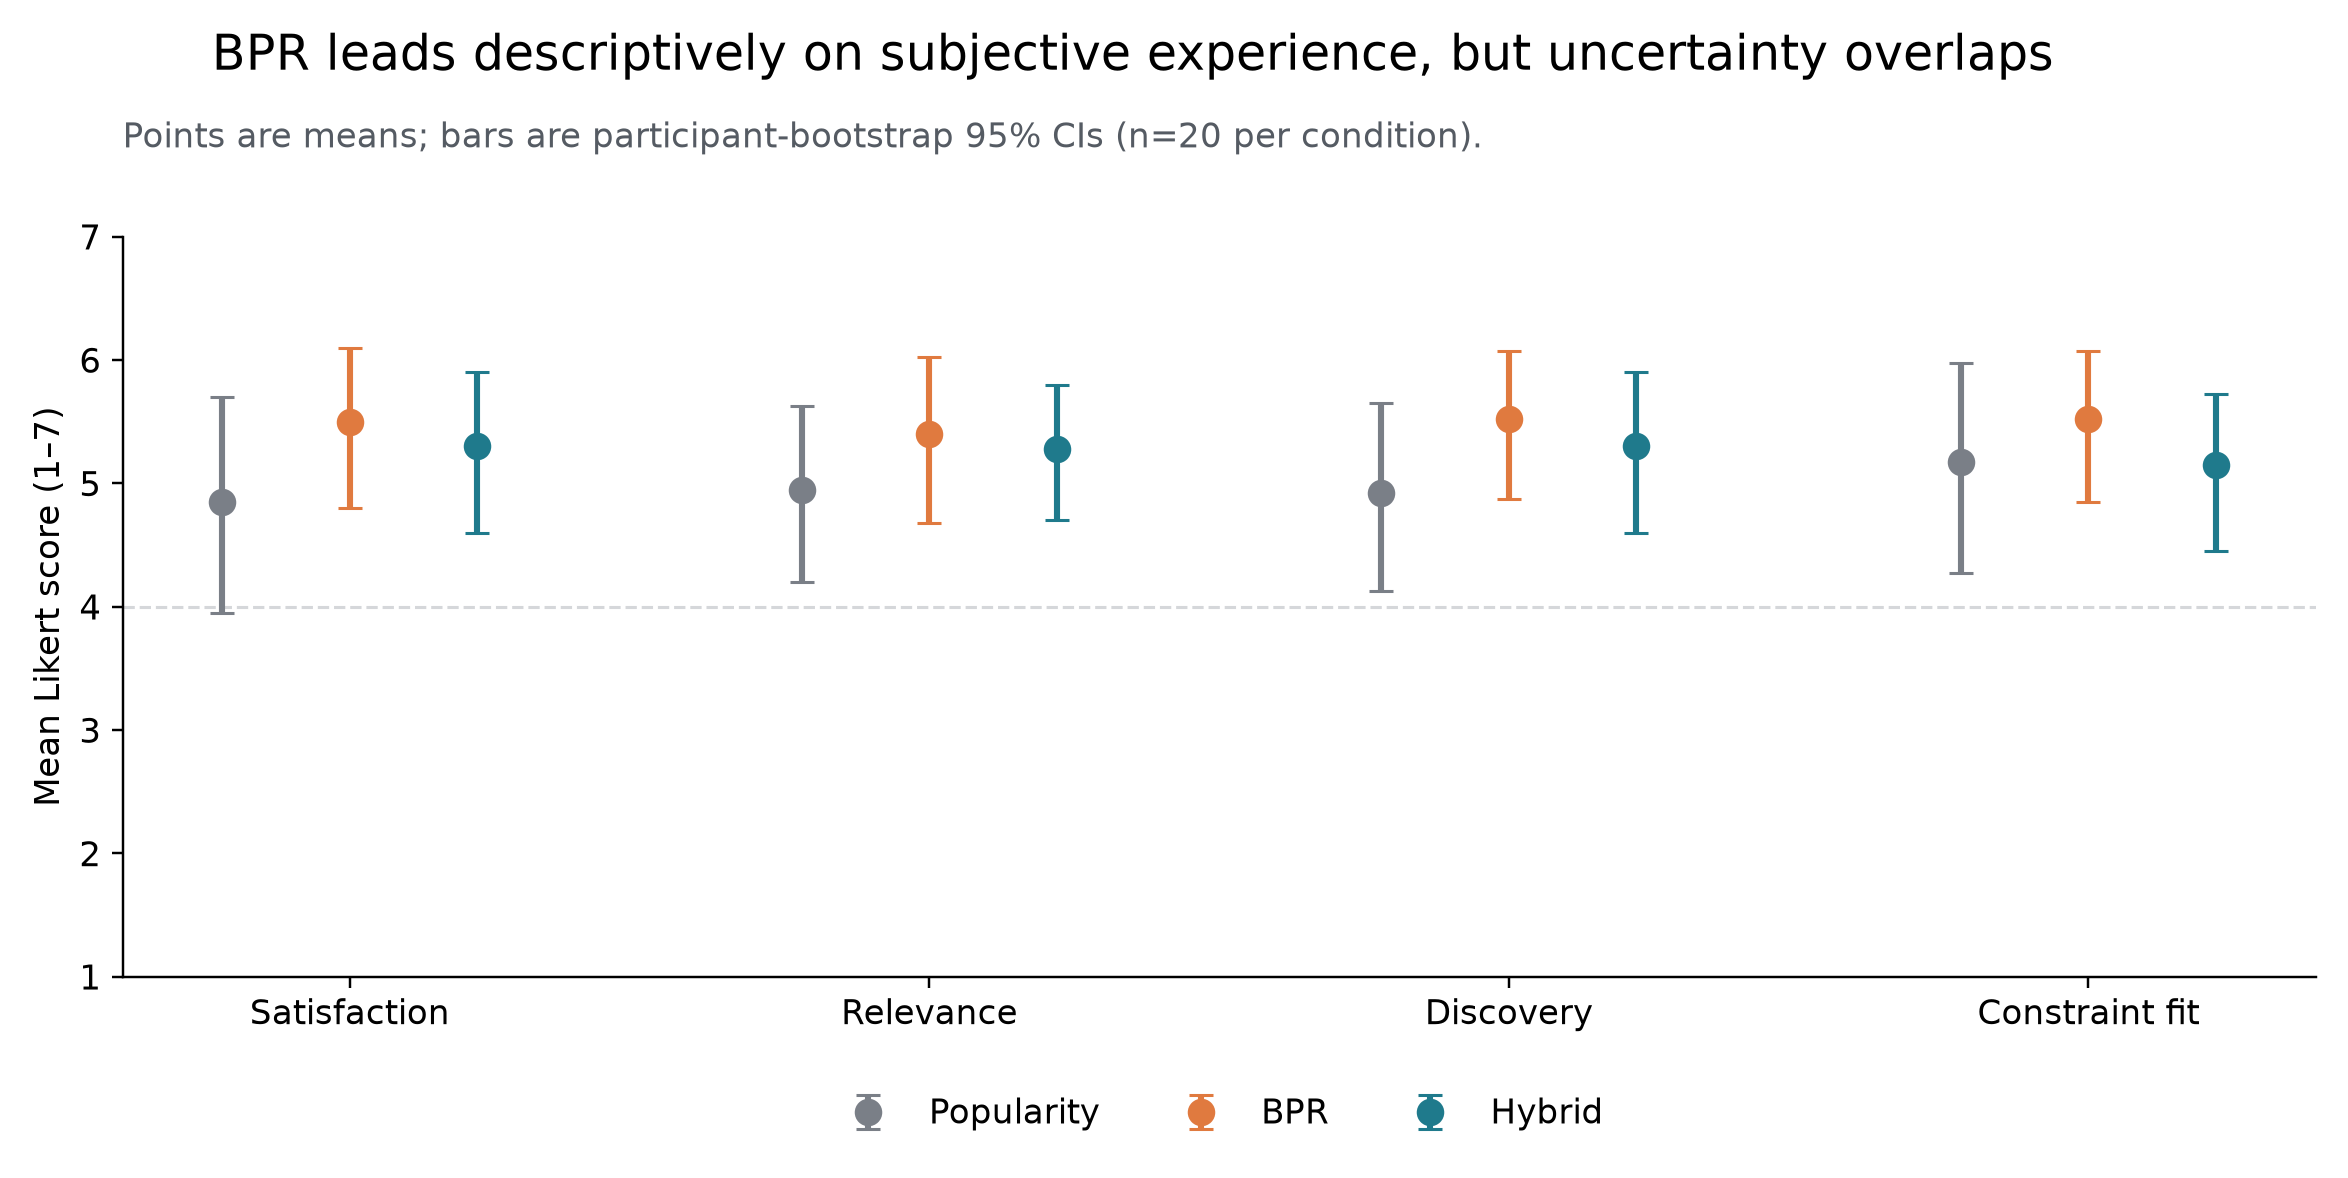

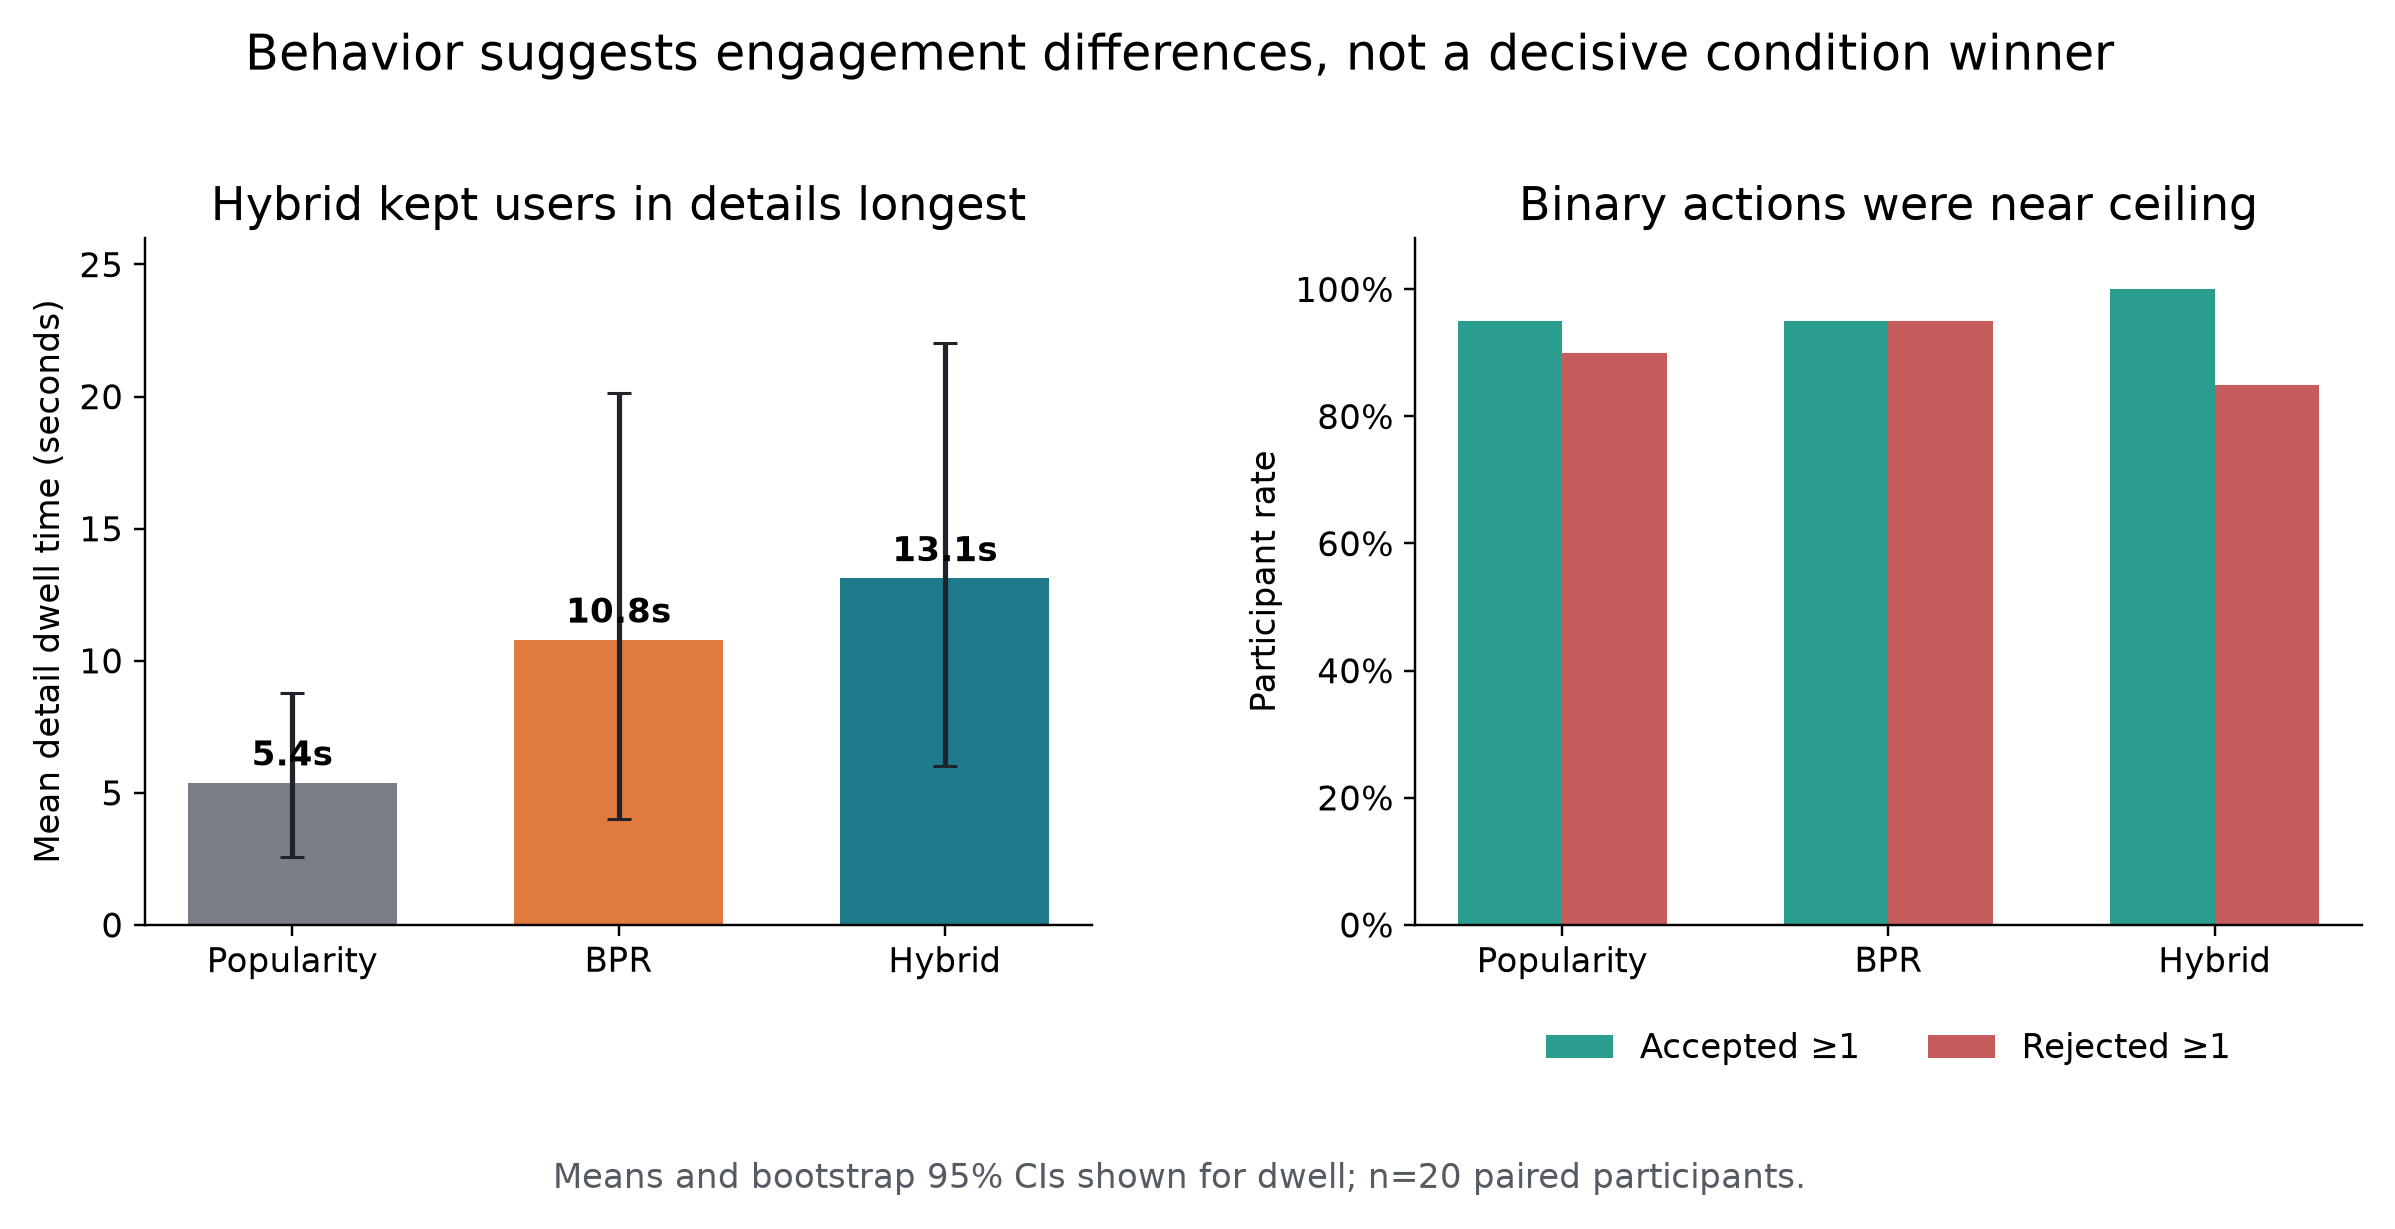

In [10]:
study_summary = json.loads(PATHS["study_summary"].read_text())
conditions = pd.read_csv(PATHS["condition_summary"])
omnibus = pd.read_csv(PATHS["study_omnibus"])
pairwise = pd.read_csv(PATHS["study_pairwise"])

assert study_summary["participants"] == 20
assert study_summary["participant_condition_rows"] == 60
assert study_summary["complete_three_round_participants"] == 20
assert set(conditions["condition"]) == {"A", "B", "C"}
assert (conditions["participant_conditions"] == 20).all()

display(conditions)
display(omnibus[["outcome_label", "test", "n_complete", "statistic", "p_value", "p_holm_across_outcomes", "significant_holm_0_05"]])

primary_pairs = pairwise[pairwise["outcome"] == "q10_satisfaction"]
display(primary_pairs[["comparison", "left_model", "right_model", "mean_difference_right_minus_left", "p_value", "p_holm_within_outcome", "significant_holm_0_05"]])
assert not omnibus["significant_holm_0_05"].any()
assert not pairwise["significant_holm_0_05"].any()
display(Image(filename=str(ROOT / "study/results/figures/online-experience-means.png"), width=800))
display(Image(filename=str(ROOT / "study/results/figures/behavioral-outcomes.png"), width=800))

### Online–offline relationship

The 60 within-subject rows are not independent and offline NDCG@10 is almost entirely zero. Correlations are therefore descriptive only. A numeric coefficient is not evidence of a positive or negative relationship when its clustered interval spans zero and the predictor has almost no variation.

,scope,outcome,method,usable_pairs,offline_zero_rate,correlation,cluster_bootstrap_ci_low,cluster_bootstrap_ci_high
0,pooled,q10_satisfaction,spearman,60,0.966667,-0.082403,-0.194249,0.011119
1,pooled,q10_satisfaction,pearson,60,0.966667,-0.023479,-0.115842,0.041431


Offline NDCG@10 is zero in **96.7%** of participant-condition rows (58/60). The current sample therefore cannot estimate a reliable online–offline association.

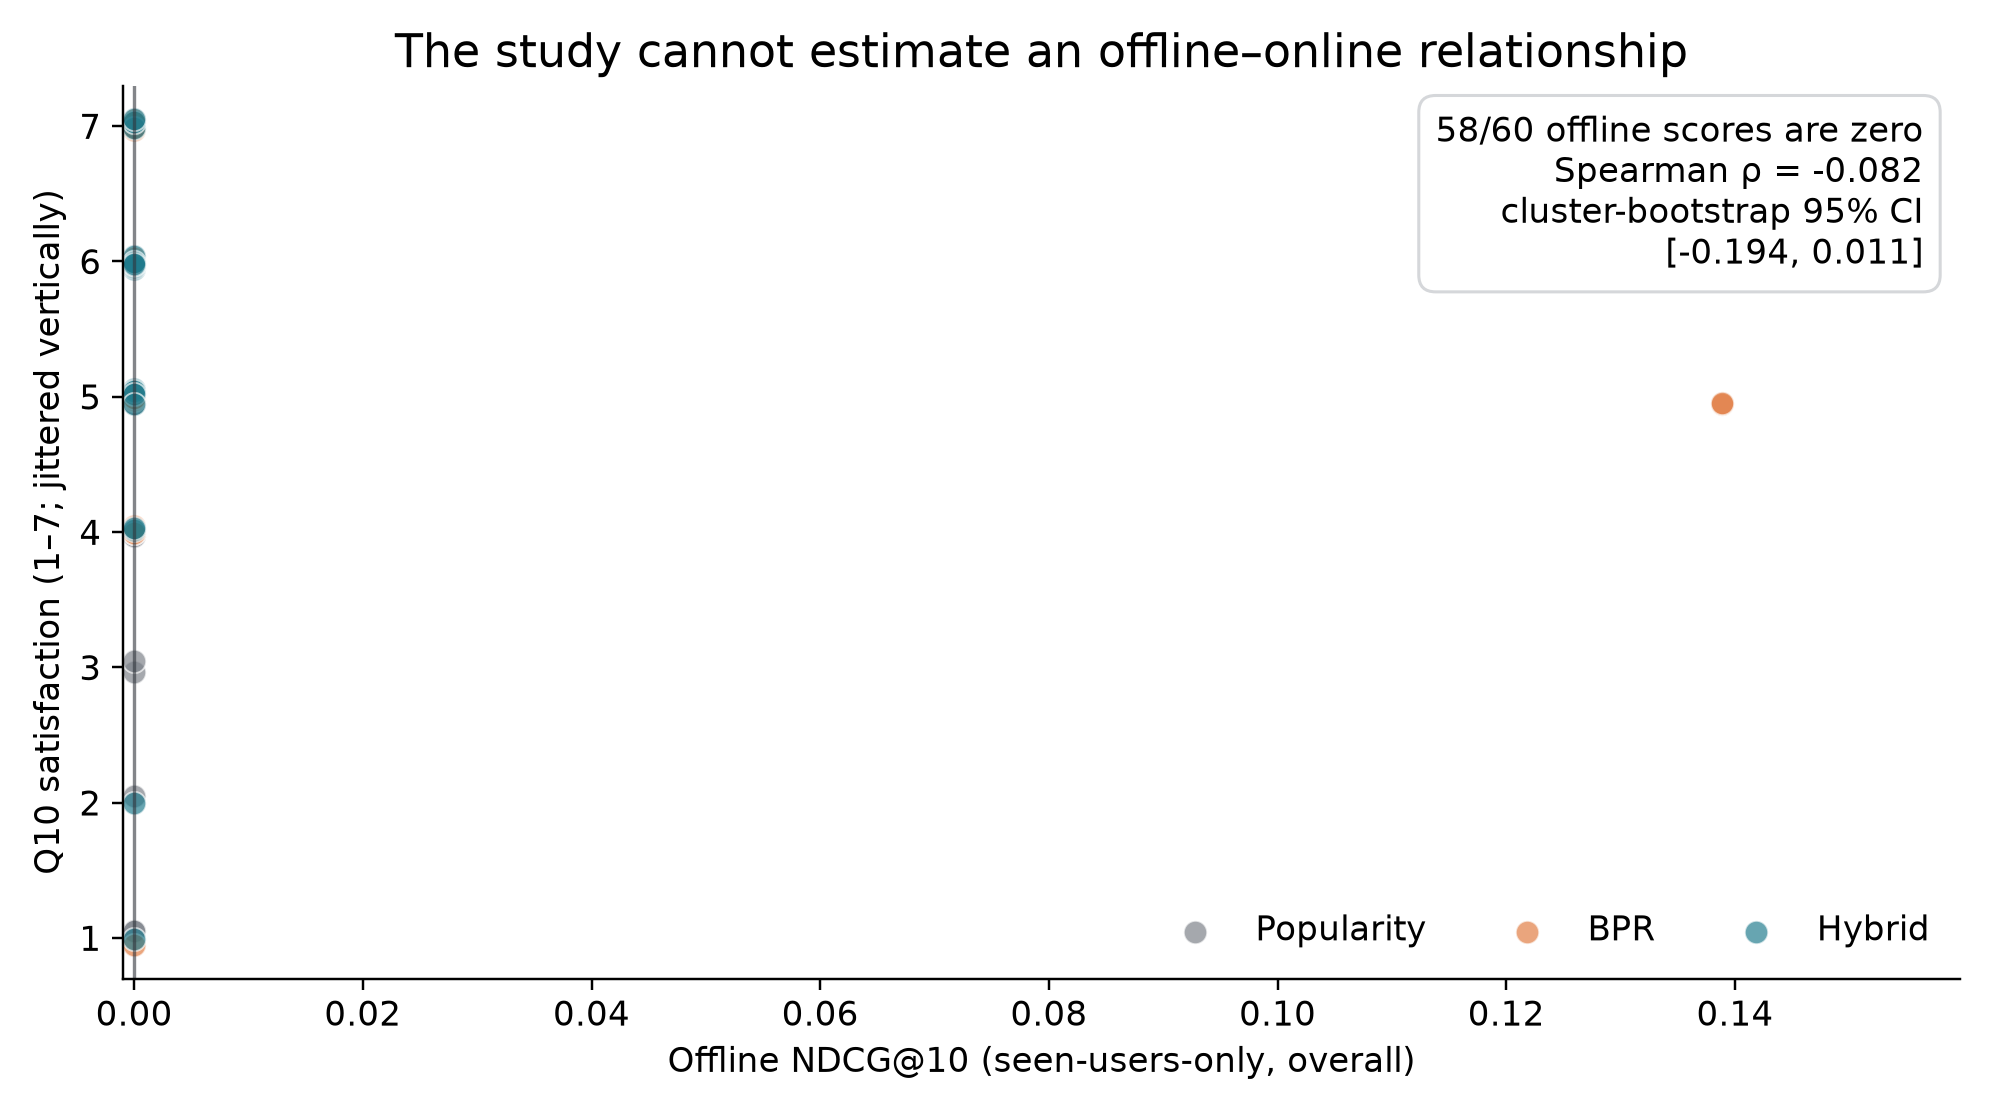

In [11]:
correlations = pd.read_csv(PATHS["correlations"])
primary_corr = correlations[
    (correlations["scope"] == "pooled")
    & (correlations["outcome"] == "q10_satisfaction")
]
display(primary_corr)

zero_rate = study_summary["offline_ndcg_zero_rate"]
assert zero_rate == 58 / 60
assert (
    (primary_corr["cluster_bootstrap_ci_low"] <= 0)
    & (primary_corr["cluster_bootstrap_ci_high"] >= 0)
).all()
display(
    Markdown(
        f"Offline NDCG@10 is zero in **{zero_rate:.1%}** of participant-condition rows (58/60). "
        "The current sample therefore cannot estimate a reliable online–offline association."
    )
)
display(Image(filename=str(ROOT / "study/results/figures/offline-online-correlation.png"), width=760))

## 8. Deployment evidence

The final system is more than its ranker: all three study conditions pass through seen-item exclusion, hard constraint filters, and deterministic MMR. The benchmark measures the warm in-memory service path; it excludes startup, data loading and browser/network latency.

In [12]:
benchmark = json.loads(PATHS["serving_benchmark"].read_text())
latency = pd.DataFrame(benchmark["by_condition"]).T.reset_index(names="condition")
latency = latency[["condition", "runs", "mean_ms", "p50_ms", "p95_ms", "p99_ms", "max_ms"]]
display(latency)
display(pd.DataFrame([benchmark["overall"]], index=["overall"]))
print("Benchmark limitation:", " ".join(benchmark["limitations"]))

,condition,runs,mean_ms,p50_ms,p95_ms,p99_ms,max_ms
0,A,230.0,31.019595,12.210542,69.968167,75.042500,82.086750
1,B,230.0,106.851893,27.124125,288.113458,304.646500,317.800583
2,C,230.0,106.479977,30.280875,278.303250,297.531333,306.308334


,runs,mean_ms,p50_ms,p95_ms,p99_ms,max_ms
overall,690,81.450488,18.879459,273.038209,300.679667,317.800583


Benchmark limitation: This is a local single-process service-layer benchmark, not browser network latency. The input is the formally validated three-model study package.


## 9. Final selection reasoning

There is no defensible universal winner:

1. **ItemCF is the offline ranking-accuracy winner** on the common seen-user holdout.
2. **BPR provides the widest catalogue coverage and highest novelty** and has the highest observed mean satisfaction in the 20-person study, but the within-subject difference is not statistically significant.
3. **Hybrid is the deployment proposal for mixed and cold-start use** because it combines competitive offline accuracy, broad coverage, content-only support for unseen items, the longest observed detail dwell, and the lowest observed rejection rate. These online differences are descriptive, not proven effects.
4. **Popularity remains a transparent fallback**, not the final personalized ranker.

The conclusion is deliberately layered: report ItemCF as the offline winner, preserve BPR as the exploration/coverage alternative used in the study, and deploy Hybrid when content-aware cold-start resilience is required. The common filtering and MMR service layer remains model-independent.

In [13]:
itemcf = comparison.loc[comparison["model"] == "itemcf"].iloc[0]
bpr = comparison.loc[comparison["model"] == "bpr"].iloc[0]
hybrid_row = comparison.loc[comparison["model"] == "hybrid"].iloc[0]
b_condition = conditions.loc[conditions["condition"] == "B"].iloc[0]
c_condition = conditions.loc[conditions["condition"] == "C"].iloc[0]

display(
    Markdown(
        "### Evidence-backed final statement\n\n"
        f"ItemCF leads offline NDCG@10 at **{itemcf.ndcg_at_k:.4f}**. "
        f"BPR leads catalogue coverage at **{bpr.catalogue_coverage:.3f}** and novelty at **{bpr.novelty:.2f}**, "
        f"while its observed satisfaction mean is **{b_condition.satisfaction_mean:.2f}/7**. "
        f"Hybrid reaches offline NDCG@10 **{hybrid_row.ndcg_at_k:.4f}**, content-only cold-item NDCG@10 "
        f"**{content_only:.4f}**, observed dwell **{c_condition.dwell_seconds_mean:.2f}s**, and rejection rate "
        f"**{c_condition.rejection_rate:.2f}**. No user-study outcome survives Holm correction."
    )
)
print("Notebook completed successfully: all evidence and consistency assertions passed.")

### Evidence-backed final statement

ItemCF leads offline NDCG@10 at **0.0385**. BPR leads catalogue coverage at **0.162** and novelty at **10.83**, while its observed satisfaction mean is **5.50/7**. Hybrid reaches offline NDCG@10 **0.0288**, content-only cold-item NDCG@10 **0.0488**, observed dwell **13.11s**, and rejection rate **0.85**. No user-study outcome survives Holm correction.

Notebook completed successfully: all evidence and consistency assertions passed.


## 10. Limitations

- The user study has 20 participants; it is adequate for the planned exploratory within-subject evaluation but underpowered for small effects.
- Offline NDCG@10 is zero for 58/60 participant-condition rows, so the online–offline association cannot be estimated reliably.
- Detail-page interaction is shallow and dwell time is noisy; it is treated as a secondary behavioral outcome.
- The serving benchmark is local and warm in-memory, not end-to-end network latency.
- C's post-study BPR update is reproducible code evidence only; it was not substituted into the frozen user-study condition.